In [1]:
# Parameters
name      = ""
fits_path = ""

In [2]:
# Parameters
name = "FLAMES-30Dor-Ha-bin0-grid_2"
fits_path = "fits_ready/FLAMES-30Dor-Ha-bin0-grid_2.fits"


In [3]:
import time
start_time=time.time()

In [4]:
import numpy as np
import seaborn as sns
import pandas as pd
import sys
from pathlib import Path
import astropy.units as u
from matplotlib import pyplot as plt
import corner
import json
from astropy.io import fits
from lmfit.model import save_modelresult


# Add path to py_modules 
sys.path.append(str(Path().resolve() / 'py_modules')) # 1 level up = project root

#import strucfunc                   
import strucfunc
import fit_structure_function
import ci_results_compiler
import bfunc
import bplot

In [5]:
from astropy.table import Table

data_in = Table.read("fits_ready/FLAMES-30Dor-6563-reg.fits", hdu=1)
data_frame = data_in.to_pandas()

# Velocity Field

In [6]:
# Loading obs
hdul = fits.open(fits_path)
hdr = hdul[0].header
print(hdul.info())
print(hdr)
sb = hdul['MOM0'].data.astype(float)
vv= hdul['MOM1'].data.astype(float)

Filename: fits_ready/FLAMES-30Dor-Ha-bin0-grid_2.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU      23   ()      
  1  MOM0          1 ImageHDU        30   (32, 30)   float64   
  2  MOM1          1 ImageHDU        30   (32, 30)   float64   
  3  MOM2          1 ImageHDU        30   (32, 30)   float64   
  4  MASK          1 ImageHDU        30   (32, 30)   uint8   
  5  TABLE         1 BinTableHDU     34   32R x 11C   [D, D, D, D, K, D, D, D, D, D, D]   
  6  TABLE         1 BinTableHDU     34   32R x 11C   [D, D, D, D, K, D, D, D, D, D, D]   
None
SIMPLE  =                    T / conforms to FITS standard                      BITPIX  =                    8 / array data type                                NAXIS   =                    0 / number of array dimensions                     EXTEND  =                    T                                                  FILE    = 'FLAMES-30Dor-Ha-bin0' / Fits file name                       

None
SIMPLE  =                    T / conforms to FITS standard                      BITPIX  =                    8 / array data type                                NAXIS   =                    0 / number of array dimensions                     EXTEND  =                    T                                                  FILE    = 'FLAMES-30Dor-Ha-bin0' / Fits file name                               NAME_ID = 'FLAMES-30Dor-Ha-bin0' / pipeline identifier                          REG     = 'NGC 2070'           / Region catalog name                            NAME_REG= '30 Doradus'         / Region name                                    REG_ID  = '30Dor   '           / Region identifier                              TYPE_OBJ= 'H II region'        / Type object                                    DIST    =                50000 / Distance in parsecs                            INSTR   = 'FLAMES  '           / Instrument                                     LINE    = 'H$\alpha$'          / Em

In [7]:
with fits.open(fits_path) as hdul:
    hdr = hdul[0].header

hdr

SIMPLE  =                    T / conforms to FITS standard                      
BITPIX  =                    8 / array data type                                
NAXIS   =                    0 / number of array dimensions                     
EXTEND  =                    T                                                  
FILE    = 'FLAMES-30Dor-Ha-bin0' / Fits file name                               
NAME_ID = 'FLAMES-30Dor-Ha-bin0' / pipeline identifier                          
REG     = 'NGC 2070'           / Region catalog name                            
NAME_REG= '30 Doradus'         / Region name                                    
REG_ID  = '30Dor   '           / Region identifier                              
TYPE_OBJ= 'H II region'        / Type object                                    
DIST    =                50000 / Distance in parsecs                            
INSTR   = 'FLAMES  '           / Instrument                                     
LINE    = 'H$\alpha$'       

In [8]:
#m3D      = hdul[0].header['M3D']
#ra       = hdul[0].header['RA']
sig      = hdul[0].header['SIG']
sig2     = hdul[0].header['SIG2']
s0       = hdul[0].header['S0']
#noise    = hdul[0].header['NOISE']
box_size = hdul[0].header['BOX_SIZE']
pc       = hdul[0].header['PC']
pix      = hdul[0].header['PIX']
line     = hdul[0].header['LINE']
binsize  = hdul[0].header['BINSIZE']

C:\Users\javas\AppData\Local\Temp\ipykernel_35656\2320504042.py:9: RuntimeWarning: divide by zero encountered in log10
  im = ax.imshow(np.log10(sb), **imshow_kwds)


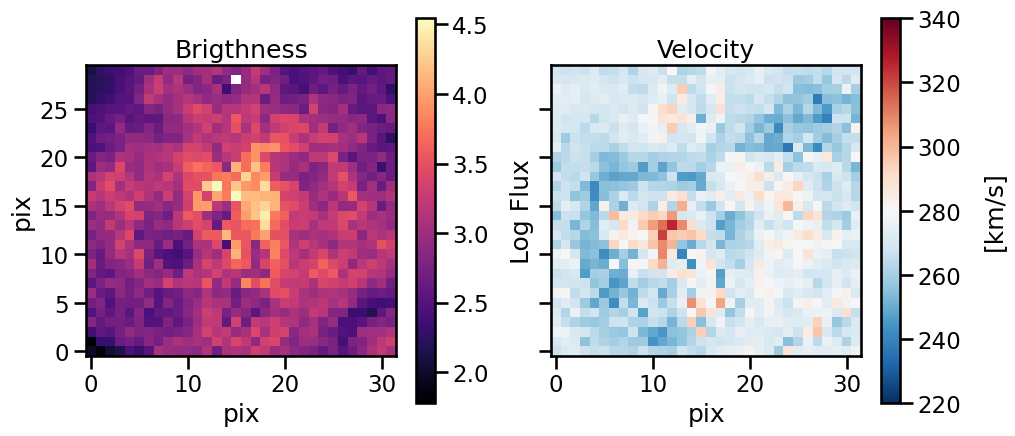

<Figure size 640x480 with 0 Axes>

In [9]:
fig, (ax, axx) = plt.subplots(
    1,
    2,
    sharey=True,
    figsize=(11, 5),
)

imshow_kwds = dict(origin="lower", cmap="magma")
im = ax.imshow(np.log10(sb), **imshow_kwds)
cbar = fig.colorbar(im, ax=[ax])
cbar.set_label("Log Flux", rotation=90, labelpad=15)

imshow_kwds2 = dict(origin="lower", cmap="RdBu_r")
im = axx.imshow(vv,vmin=220,vmax=340, **imshow_kwds2)
cbar = fig.colorbar(im, ax=[axx])
cbar.set_label("[km/s]", rotation=90, labelpad=15)

ax.set_xlabel("pix")
ax.set_ylabel("pix")
axx.set_xlabel("pix")
ax.set_title("Brigthness")
axx.set_title("Velocity")

plt.show()

plt.savefig(name + '.jpg', bbox_inches='tight')

In [10]:
from astropy.wcs import WCS
from astropy.io import fits

# Read the spatial WCS from each moment extension.
with fits.open(fits_path) as hdul:
    wcs_sb = WCS(hdul["MOM0"].header).celestial
    wcs_vv = WCS(hdul["MOM1"].header).celestial

if not (wcs_sb.has_celestial and wcs_vv.has_celestial):
    raise ValueError("The moment extension headers lack celestial WCS.")

C:\Users\javas\AppData\Local\Temp\ipykernel_35656\2071496408.py:10: RuntimeWarning: divide by zero encountered in log10
  im = ax.imshow(np.log10(sb), origin="lower", cmap="magma")


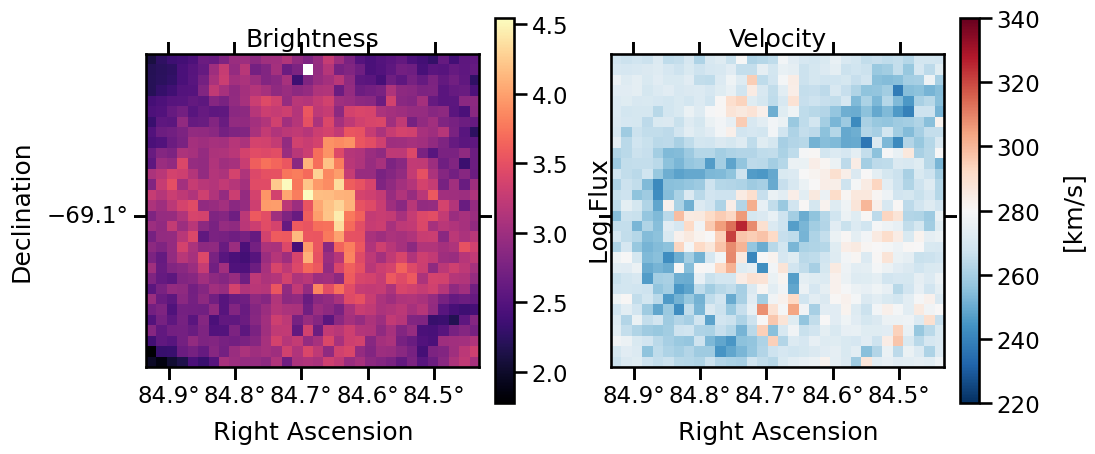

In [11]:
fig, (ax, axx) = plt.subplots(
    1,
    2,
    sharey=True,
    figsize=(11, 5),
    subplot_kw={"projection": wcs_sb},
)

# Brightness
im = ax.imshow(np.log10(sb), origin="lower", cmap="magma")
cbar = fig.colorbar(im, ax=ax, fraction=0.1, pad=0.04)
cbar.set_label("Log Flux", rotation=90, labelpad=15)

# Velocity
im = axx.imshow(
    vv, vmin=220, vmax=340,
    origin="lower", cmap="RdBu_r",
)
cbar = fig.colorbar(im, ax=axx, fraction=0.1, pad=0.04)
cbar.set_label("[km/s]", rotation=90, labelpad=15)

for axis in (ax, axx):
    axis.coords[0].set_axislabel("Right Ascension")
    axis.coords[0].set_major_formatter("d.d")
    axis.coords[1].set_major_formatter("d.d")

ax.coords[1].set_axislabel("Declination")

# Show declination labels only on the left panel.
axx.coords[1].set_ticklabel_visible(False)
axx.coords[1].set_axislabel("")

ax.set_title("Brightness")
axx.set_title("Velocity")

fig.savefig(name + ".jpg", dpi=300, bbox_inches="tight")
plt.show()

In [12]:
import numpy as np
import pandas as pd
from astropy.io import fits
from astropy.wcs import WCS
from astropy.coordinates import SkyCoord
import astropy.units as u

# ============================================================
# 1. USER INPUTS
# ============================================================

fibres = data_frame.copy()

RA_COL = "RAdeg"
DEC_COL = "DEdeg"

# Maximum distance between fibre position and nearest pixel
# centre, measured in pixels. Inspect the offsets below.
MAX_OFFSET_PIX = 0.25

# ============================================================
# 2. LOAD ORIGINAL MOMENT MAPS AND WCS
# ============================================================

with fits.open(fits_path) as hdul:
    sb_original = hdul["MOM0"].data.astype(float).copy()
    vv_original = hdul["MOM1"].data.astype(float).copy()
    wcs_cube = WCS(hdul["MOM1"].header).celestial

if not wcs_cube.has_celestial:
    raise ValueError("MOM1 does not contain celestial WCS.")

if sb_original.shape != vv_original.shape:
    raise ValueError("MOM0 and MOM1 have different shapes.")

# Assumes MOM0 and MOM1 share the same spatial pixel grid.
ny, nx = vv_original.shape

# ============================================================
# 3. CONVERT FIBRE COORDINATES TO CUBE PIXELS
# ============================================================

ra = fibres[RA_COL].to_numpy(dtype=float)
dec = fibres[DEC_COL].to_numpy(dtype=float)

finite_coords = np.isfinite(ra) & np.isfinite(dec)
fibres = fibres.loc[finite_coords].copy()

coords = SkyCoord(
    ra=ra[finite_coords] * u.deg,
    dec=dec[finite_coords] * u.deg,
    frame="icrs",
)

# Floating-point coordinates; integer coordinates are pixel centres.
x, y = wcs_cube.world_to_pixel(coords)

inside = (
    np.isfinite(x) & np.isfinite(y)
    & (x >= -0.5) & (x < nx - 0.5)
    & (y >= -0.5) & (y < ny - 0.5)
)

matches = fibres.loc[inside].copy()
matches["x_pixel"] = x[inside]
matches["y_pixel"] = y[inside]

ix = np.floor(x[inside] + 0.5).astype(int)
iy = np.floor(y[inside] + 0.5).astype(int)

matches["ix"] = ix
matches["iy"] = iy
matches["offset_pix"] = np.hypot(x[inside] - ix, y[inside] - iy)

matches["cube_velocity"] = vv_original[iy, ix]
matches["cube_brightness"] = sb_original[iy, ix]

# Same positive-brightness requirement used in the SF preparation.
matches["accepted"] = (
    (matches["offset_pix"] <= MAX_OFFSET_PIX)
    & np.isfinite(matches["cube_velocity"])
    & np.isfinite(matches["cube_brightness"])
    & (matches["cube_brightness"] > 0)
)

matched = matches.loc[matches["accepted"]].copy()

# ============================================================
# 4. DIAGNOSTICS
# ============================================================

print(f"Input fibres:                  {len(data_frame)}")
print(f"Finite fibre coordinates:      {len(fibres)}")
print(f"Inside cube footprint:         {len(matches)}")
print(f"Accepted matches:              {len(matched)}")

print("\nOffsets for fibres inside the footprint [pixels]:")
print(matches["offset_pix"].describe())

if matched.empty:
    raise ValueError("No matches accepted. Inspect the WCS and offsets.")

duplicates = matched.duplicated(["iy", "ix"], keep=False)

if duplicates.any():
    print(matched.loc[duplicates, [RA_COL, DEC_COL, "ix", "iy"]])
    raise ValueError(
        "Multiple fibres map to the same cube pixel. "
        "Resolve these before making a one-to-one comparison."
    )

# ============================================================
# 5. BUILD THE FIBRE-POSITION MASK
# ============================================================

keep = np.zeros(vv_original.shape, dtype=bool)

keep[
    matched["iy"].to_numpy(),
    matched["ix"].to_numpy(),
] = True

velocity_masked = np.where(keep, vv_original, np.nan)
sb_masked = np.where(keep, sb_original, np.nan)

# Variables used by your existing plotting and SF cells.
vv = velocity_masked
sb = sb_masked

Input fibres:                  269
Finite fibre coordinates:      269
Inside cube footprint:         269
Accepted matches:              269

Offsets for fibres inside the footprint [pixels]:
count    269.000000
mean       0.035701
std        0.030087
min        0.000404
25%        0.011638
50%        0.025630
75%        0.052564
max        0.139518
Name: offset_pix, dtype: float64


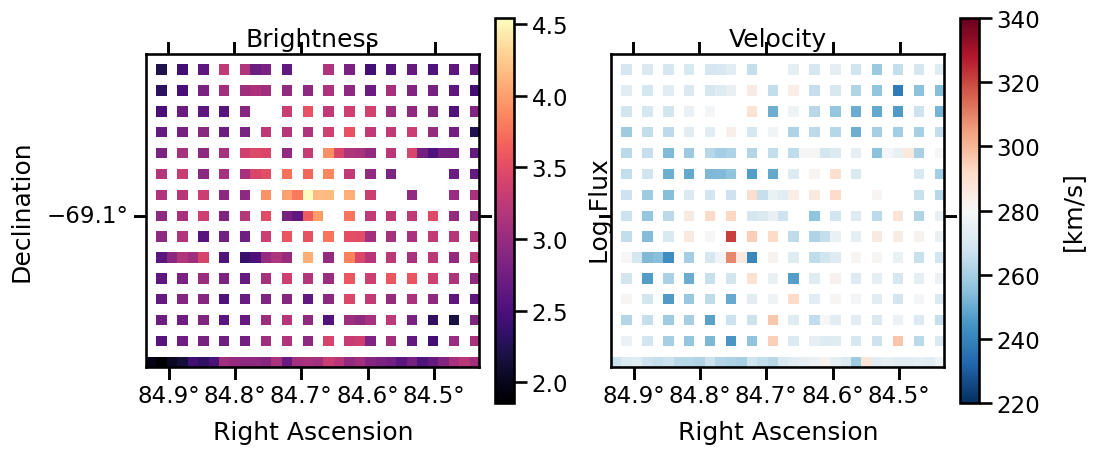

In [13]:
fig, (ax, axx) = plt.subplots(
    1,
    2,
    sharey=True,
    figsize=(11, 5),
    subplot_kw={"projection": wcs_sb},
)

# Brightness
im = ax.imshow(np.log10(sb), origin="lower", cmap="magma")
cbar = fig.colorbar(im, ax=ax, fraction=0.1, pad=0.04)
cbar.set_label("Log Flux", rotation=90, labelpad=15)

# Velocity
im = axx.imshow(
    vv, vmin=220, vmax=340,
    origin="lower", cmap="RdBu_r",
)
cbar = fig.colorbar(im, ax=axx, fraction=0.1, pad=0.04)
cbar.set_label("[km/s]", rotation=90, labelpad=15)

for axis in (ax, axx):
    axis.coords[0].set_axislabel("Right Ascension")
    axis.coords[0].set_major_formatter("d.d")
    axis.coords[1].set_major_formatter("d.d")

ax.coords[1].set_axislabel("Declination")

# Show declination labels only on the left panel.
axx.coords[1].set_ticklabel_visible(False)
axx.coords[1].set_axislabel("")

ax.set_title("Brightness")
axx.set_title("Velocity")

fig.savefig(name + ".jpg", dpi=300, bbox_inches="tight")
plt.show()

# Structure function

In [14]:
# Keep NaNs in vv and sb for plotting.
valid = np.isfinite(vv) & np.isfinite(sb) & (sb > 0)

if np.count_nonzero(valid) < 2:
    raise ValueError("Fewer than two valid pixels remain.")

# Separate computational arrays:
# excluded pixels have finite placeholder velocities and zero weights.
vv_sf = np.where(valid, vv, np.nanmean(vv))
sb_sf = np.where(valid, sb, 0.0)

In [15]:
#rslt = strucfunc.strucfunc_numba_parallel(vv, wmap=sb, dlogr=0.05)

rslt = strucfunc.strucfunc_numba_parallel(
    vv_sf,
    wmap=sb_sf,
    dlogr=0.05,
    wmin_factor=0.0,
)

C:\Users\javas\Dropbox\GitHub\VIENTO\structure_function_analysis\FLAMES_30dor\FLAMES_regular_cube\py_modules\strucfunc.py:83: RuntimeWarning: invalid value encountered in divide
  'Unweighted B(r)': sf/nsf,
C:\Users\javas\Dropbox\GitHub\VIENTO\structure_function_analysis\FLAMES_30dor\FLAMES_regular_cube\py_modules\strucfunc.py:84: RuntimeWarning: invalid value encountered in divide
  'Weighted B(r)': wsf/weight}


In [16]:
rslt_ = pd.DataFrame(rslt)

In [17]:
#rslt["Unweighted mean velocity"] = np.mean(vv)
#rslt["Unweighted sigma^2"] = np.var(vv)
#v0w = rslt["Weighted mean velocity"] = np.average(vv, weights=sb)
#rslt["Weighted sigma^2"] = np.average((vv - v0w)**2, weights=sb)

In [18]:
v = vv[valid]
w = sb[valid]

rslt["Unweighted mean velocity"] = np.mean(v)
rslt["Unweighted sigma^2"] = np.var(v)

v0w = np.average(v, weights=w)
rslt["Weighted mean velocity"] = v0w
rslt["Weighted sigma^2"] = np.average((v - v0w)**2, weights=w)

# Build the dataframe AFTER adding the statistics.
rslt_ = pd.DataFrame(rslt)

In [19]:
#rslt_

In [20]:
b2    = rslt['Unweighted B(r)']
b2w   = rslt['Weighted B(r)']
e_b2  = b2  *.1
e_b2w = b2w  *.1

s     = 10**rslt['log10 r'] * pix * pc
e_s   = s  *.1
sig2  = rslt['Unweighted sigma^2']
sig2w = rslt['Weighted sigma^2']

sig   = sig2**0.5

In [21]:
b2w

array([ 80.49822599,          nan,          nan,          nan,
                nan,          nan, 156.86402451,          nan,
                nan, 300.17592103,          nan, 372.88519873,
       177.65348075, 310.95799155, 360.0749217 , 320.99231487,
       345.65726941, 274.64376433, 370.33759716, 310.51913795,
       292.97827685, 297.95689252, 285.31590532, 291.83249387,
       282.70126831, 285.41165824, 255.34267037, 241.96522494,
       193.19313295, 125.96906699,  99.51687629,  69.49368946])

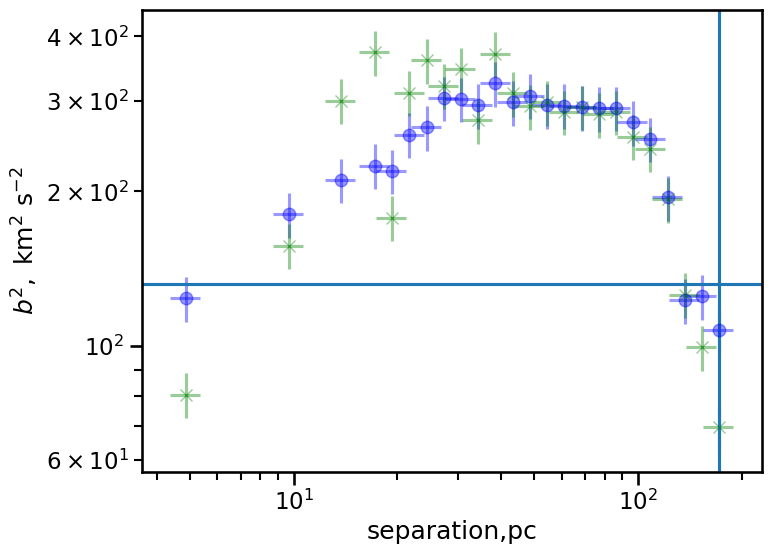

In [22]:
r0    = np.interp(sig2, b2[1:35], s[1:35])
ra = r0
m     = 1
noise = 0

rgrid = np.linspace(s[0], s[:-1])

fig, ax = plt.subplots(figsize=(8, 6))

ax.errorbar(s, b2, yerr=e_b2, xerr=e_s, fmt='o', alpha=0.4,color="blue")
ax.errorbar(s, b2w, yerr=e_b2w, xerr=e_s, fmt='x', alpha=0.4,color="green")

ax.axhline(sig2, ls='-')
ax.axvline(r0, ls='-')

#ax.plot(rgrid, bfunc.bfunc00s(rgrid, r0, sig2, m), color="0.8")
#ax.plot(rgrid, bfunc.bfunc03s(rgrid, r0, sig2, m, s0, noise), color="black")
#ax.plot(rgrid, bfunc.bfunc04s(rgrid, r0, sig2, m, s0, noise, box_size), color="black")


ax.set(xscale='log', yscale='log', 
       xlabel='separation,pc',
       ylabel=r'$b^2,\ \mathrm{km^2\ s^{-2}}$'
      )
None

plt.show()



# Export

In [30]:
from astropy.table import Table


df =  rslt_.copy()

# Flatten MultiIndex columns like ('s','count') -> "s_count"
if isinstance(df.columns, pd.MultiIndex):
    df.columns = ["_".join(map(str, col)).strip() for col in df.columns.to_flat_index()]
else:
    df.columns = [str(c) for c in df.columns]

# (Optional) drop index to avoid it becoming an extra column
df = df.reset_index(drop=True)

t = Table.from_pandas(df)
new_hdu = fits.BinTableHDU(t, name="TABLE")

In [31]:
# Remove ALL previous TABLE extensions, preserving other HDUs.
with fits.open(fits_path) as hdul:
    hdus = [
        h.copy()
        for h in hdul
        if h.name.upper() != "TABLE"
    ]

new_hdu.header["MASKTYPE"] = "REGULAR"
#new_hdu.header["MASKPHAS"] = int(phase)
new_hdu.header["NVALID"] = int(valid.sum())
new_hdu.header["WMINFAC"] = 0.0

hdus.append(new_hdu)

with fits.HDUList(hdus) as output:
    output.writeto(fits_path, overwrite=True)

# Verify that exactly one table exists and matches this run.
with fits.open(fits_path) as check:
    assert sum(h.name.upper() == "TABLE" for h in check) == 1

    for column in ("Unweighted B(r)", "Weighted B(r)"):
        np.testing.assert_allclose(
            check["TABLE"].data[column],
            np.asarray(rslt[column]),
            equal_nan=True,
        )

print("Current structure-function table saved:", Path(fits_path).resolve())

Current structure-function table saved: C:\Users\javas\Dropbox\GitHub\VIENTO\structure_function_analysis\FLAMES_30dor\FLAMES_regular_cube\fits_ready\FLAMES-30Dor-Ha-bin0-grid_2.fits


In [32]:
with fits.open(fits_path, mode="readonly") as hdul:
    hdus = [h.copy() for h in hdul]   # copy existing HDUs

hdus.append(new_hdu)
fits.HDUList(hdus).writeto(fits_path, overwrite=True)

In [33]:
# Test import

from astropy.table import Table
t = Table.read(fits_path, hdu="TABLE")
df_loaded = t.to_pandas()
df_loaded


,log10 r,Sum dv^2,Sum weights,Sum w * dv^2,N pairs,Unweighted B(r),Weighted B(r),Unweighted mean velocity,Unweighted sigma^2,Weighted mean velocity,Weighted sigma^2
0,0.00,8.674677e+03,1.202585e+09,9.680594e+10,70,123.923955,80.498226,269.371704,132.045869,271.217365,140.841404
1,0.05,0.000000e+00,0.000000e+00,0.000000e+00,0,NaN,NaN,269.371704,132.045869,271.217365,140.841404
2,0.10,0.000000e+00,0.000000e+00,0.000000e+00,0,NaN,NaN,269.371704,132.045869,271.217365,140.841404
3,0.15,0.000000e+00,0.000000e+00,0.000000e+00,0,NaN,NaN,269.371704,132.045869,271.217365,140.841404
4,0.20,0.000000e+00,0.000000e+00,0.000000e+00,0,NaN,NaN,269.371704,132.045869,271.217365,140.841404
5,0.25,0.000000e+00,0.000000e+00,0.000000e+00,0,NaN,NaN,269.371704,132.045869,271.217365,140.841404
6,0.30,6.078682e+04,3.064215e+09,4.806651e+11,337,180.376324,156.864025,269.371704,132.045869,271.217365,140.841404
7,0.35,0.000000e+00,0.000000e+00,0.000000e+00,0,NaN,NaN,269.371704,132.045869,271.217365,140.841404
8,0.40,0.000000e+00,0.000000e+00,0.000000e+00,0,NaN,NaN,269.371704,132.045869,271.217365,140.841404
9,0.45,9.827853e+04,2.901513e+09,8.709642e+11,467,210.446529,300.175921,269.371704,132.045869,271.217365,140.841404


In [27]:
print("--- %s seconds ---" % (time.time()-start_time))

--- 16.2122483253479 seconds ---


In [29]:
from pathlib import Path
from astropy.io import fits
import numpy as np

# ============================================================
# 1. INPUT AND OUTPUT
# ============================================================

input_path = Path(fits_path)

# Repeated runs overwrite this matched output.
output_path = input_path.with_name(
    input_path.stem + ".fits"
)

# ============================================================
# 2. COPY ORIGINAL FILE
# ============================================================

with fits.open(input_path) as hdul:
    output = fits.HDUList([hdu.copy() for hdu in hdul])

try:
    spatial_keep = np.asarray(keep, dtype=bool).copy()

    if spatial_keep.shape != output["MOM1"].data.shape:
        raise ValueError("Mask and moment maps have different shapes.")

    # Respect any existing exclusions.
    if "MASK" in output:
        original_mask = np.asarray(output["MASK"].data)

        if original_mask.shape != spatial_keep.shape:
            raise ValueError("Original MASK has a different shape.")

        spatial_keep &= (
            np.isfinite(original_mask) & (original_mask != 0)
        )

    # ========================================================
    # 3. MASK ALL MOMENTS, PRESERVING THEIR HEADERS AND WCS
    # ========================================================

    for extension in ("MOM0", "MOM1", "MOM2"):
        if extension not in output:
            raise KeyError(f"Missing {extension} extension.")

        image = np.asarray(output[extension].data, dtype=float)

        if image.shape != spatial_keep.shape:
            raise ValueError(f"{extension} has a different shape.")

        output[extension].data = np.where(
            spatial_keep, image, np.nan
        )

    # Remove old masks and SF tables.
    # The SF must be recomputed for this spatial selection.
    for index in range(len(output) - 1, 0, -1):
        if output[index].name.upper() in ("MASK", "TABLE"):
            del output[index]

    mask_hdu = fits.ImageHDU(
        data=spatial_keep.astype(np.uint8),
        header=output["MOM1"].header.copy(),
        name="MASK",
    )
    mask_hdu.header["BUNIT"] = "1"
    mask_hdu.header["MASKTYPE"] = "FIBRE"
    mask_hdu.header["NVALID"] = int(spatial_keep.sum())
    mask_hdu.header["OFFMAX"] = (
        float(MAX_OFFSET_PIX),
        "Maximum fibre-to-pixel offset [pixel]",
    )
    output.append(mask_hdu)

    # Old global velocity statistics no longer describe this sample.
    for keyword in ("SIG", "SIG2"):
        output[0].header.remove(
            keyword, remove_all=True, ignore_missing=True
        )

    output[0].header.add_history(
        "Moment maps masked to WCS-matched fibre positions."
    )
    output[0].header.add_history(
        "Previous TABLE and primary SIG/SIG2 removed; recompute."
    )

    output.writeto(output_path, overwrite=True, checksum=True)

finally:
    output.close()

# ============================================================
# 4. VERIFY SAVED MAPS AND MASK
# ============================================================

with fits.open(output_path) as check:
    np.testing.assert_array_equal(
        check["MASK"].data, spatial_keep.astype(np.uint8)
    )

    for extension in ("MOM0", "MOM1", "MOM2"):
        assert np.all(
            np.isnan(check[extension].data[~spatial_keep])
        )

print("Saved:", output_path.resolve())
print("Retained spatial pixels:", spatial_keep.sum())

Saved: C:\Users\javas\Dropbox\GitHub\VIENTO\structure_function_analysis\FLAMES_30dor\FLAMES_regular_cube\fits_ready\FLAMES-30Dor-Ha-bin0-grid_2.fits
Retained spatial pixels: 269
